# SNL: предсказанный риск РНК off-target у двух групп генов (версия 2, всё в одном)

Мини-анализ на модели **SNL (RNAOffScan v2)** из статьи Nakamae et al., 2025 (DOI: 10.3390/ijms26041723).



In [1]:
!pip install -q "transformers==4.46.3" einops triton scipy statsmodels matplotlib pandas requests

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 75.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 55.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import random, time, requests
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr, wilcoxon
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "KazukiNakamae/SNLmodel"
WINDOW_UP, WINDOW_DOWN = 20, 19   # окно 40 нт: 20 до C + C + 19 после (допущение)
THRESHOLD = 0.5
BATCH = 64
SEED = 42

GROUPS = {
    "housekeeping":    ["ACTB", "GAPDH", "RPL13A", "RPS18", "PPIA", "TBP", "HPRT1", "PGK1", "SDHA", "YWHAZ", "UBC", "B2M"],
    "tissue_specific": ["ALB", "APOA1", "TTR", "INS", "PRSS1", "CPA1", "MYH7", "TNNT2", "CKM", "SNAP25", "GFAP", "HBB"],
}
print("torch cuda:", torch.cuda.is_available())

torch cuda: True


In [3]:
# обход проверки типов конфигурации (код модели написан под старую версию transformers)
try:
    from transformers.models.auto import auto_factory
    auto_factory._BaseAutoModelClass.register = classmethod(lambda cls, *a, **k: None)
except Exception as e:
    print("патч не применён:", e)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, trust_remote_code=True, attention_probs_dropout_prob=0.1
).to(device).eval()
print("модель загружена")

device: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_layers.py
- flash_attn_triton.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

модель загружена


In [4]:
def score_windows(windows):
    probs = []
    for i in range(0, len(windows), BATCH):
        enc = tokenizer(windows[i:i+BATCH], return_tensors="pt", padding=True)
        with torch.no_grad():
            out = model(enc["input_ids"].to(device), attention_mask=enc["attention_mask"].to(device))
        probs.extend(torch.softmax(out.logits, dim=1)[:, 1].cpu().numpy().tolist())
    return np.array(probs)

# Проверка на примерах со страницы модели: ожидаем примерно 0.78 и 0.15
examples = ["GGCAGGGCTGGGGAAGCTTACTGTGTCCAAGAGCCTGCTG", "GTCATCTAACAAAAATATTCCGTTGCAGGAAAAGCAAGCT"]
print("Проверка на двух примерах:", score_windows(examples))

def get_cds(symbol):
    r = requests.get(f"https://rest.ensembl.org/lookup/symbol/homo_sapiens/{symbol}",
                     params={"expand": 1}, headers={"Content-Type": "application/json"}, timeout=30)
    r.raise_for_status()
    info = r.json()
    tid = info.get("canonical_transcript")
    if not tid:
        tid = next(t["id"] for t in info["Transcript"] if t.get("is_canonical"))
    tid = tid.split(".")[0]
    r = requests.get(f"https://rest.ensembl.org/sequence/id/{tid}",
                     params={"type": "cds"}, headers={"Content-Type": "text/plain"}, timeout=30)
    r.raise_for_status()
    return tid, r.text.strip().upper()

def get_cds_retry(symbol, tries=6):
    for k in range(tries):
        try:
            return get_cds(symbol)
        except Exception as e:
            print(f"  {symbol}: попытка {k+1} не удалась ({type(e).__name__})")
            time.sleep(3 * (k + 1))
    raise RuntimeError(f"{symbol}: не удалось скачать")

def c_windows(seq):
    wins, pos = [], []
    for i, base in enumerate(seq):
        if base == "C" and i >= WINDOW_UP and i + WINDOW_DOWN < len(seq):
            wins.append(seq[i - WINDOW_UP : i + WINDOW_DOWN + 1])
            pos.append(i)
    return wins, pos

STOP_FROM = {"CAA", "CAG", "CGA"}

def gene_metrics(seq):
    wins, pos = c_windows(seq)
    if not wins:
        return {"n_C_windows": 0, "risk_fraction": np.nan, "mean_prob": np.nan, "stop_pos_per_100codons": np.nan}
    p = score_windows(wins)
    positive = p > THRESHOLD
    stop_mask = np.array([(i % 3 == 0) and (seq[i:i+3] in STOP_FROM) for i in pos])
    return {
        "n_C_windows": len(wins),
        "risk_fraction": float(positive.mean()),
        "mean_prob": float(p.mean()),
        "stop_pos_per_100codons": float(100 * (positive & stop_mask).sum() / (len(seq) / 3)),
    }

Token indices sequence length is longer than the specified maximum sequence length for this model (11 > 10). Running this sequence through the model will result in indexing errors


Проверка на двух примерах: [0.77448392 0.14971247]


In [5]:
rows = []
for group, genes in GROUPS.items():
    for g in genes:
        try:
            tid, seq = get_cds_retry(g)
        except Exception as e:
            print("пропуск", g, e)
            continue
        gc = (seq.count("G") + seq.count("C")) / len(seq)
        m = gene_metrics(seq)
        m.update(group=group, gene=g, transcript=tid, cds_len=len(seq), gc=gc, control=False)
        rows.append(m)
        s = list(seq)
        random.Random(SEED).shuffle(s)
        mc = gene_metrics("".join(s))
        mc.update(group=group, gene=g, transcript=tid, cds_len=len(seq), gc=gc, control=True)
        rows.append(mc)
        print(g, "готово")
        time.sleep(0.5)

df = pd.DataFrame(rows)
df.to_csv("results.csv", index=False)
print(df[~df.control].groupby("group")["gene"].count())

ACTB готово
GAPDH готово
RPL13A готово
RPS18 готово
PPIA готово
TBP готово
HPRT1 готово
PGK1 готово
SDHA готово
YWHAZ готово
UBC готово
B2M готово
ALB готово
APOA1 готово
TTR готово
INS готово
PRSS1 готово
CPA1 готово
MYH7 готово
TNNT2 готово
CKM готово
SNAP25 готово
GFAP готово
HBB готово
group
housekeeping       12
tissue_specific    12
Name: gene, dtype: int64


Медианы risk_fraction: 0.427 0.344
Манн-Уитни: MannwhitneyuResult(statistic=np.float64(121.0), pvalue=np.float64(0.005107905424995494))
Спирмен risk_fraction ~ GC: SignificanceResult(statistic=np.float64(-0.8426086956521738), pvalue=np.float64(2.3966088072191335e-07))
                 count      mean       std       min       25%       50%  \
group                                                                      
housekeeping      12.0  0.510997  0.058128  0.410959  0.482865  0.513723   
tissue_specific   12.0  0.561481  0.058449  0.429508  0.542511  0.567251   

                      75%       max  
group                                
housekeeping     0.553658  0.605496  
tissue_specific  0.588058  0.645646  
group            control
housekeeping     False      0.427021
                 True       0.403738
tissue_specific  False      0.343559
                 True       0.344019
Name: risk_fraction, dtype: float64
                                  coef    std err          t     

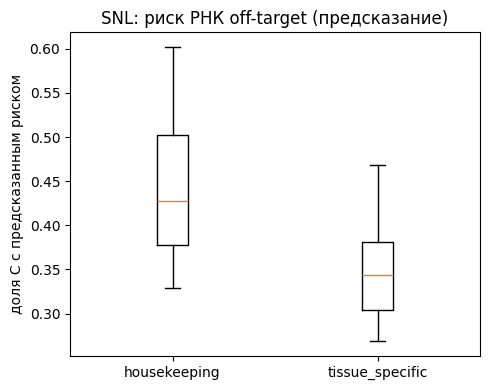

In [6]:
real = df[~df.control]
a = real[real.group == "housekeeping"]["risk_fraction"].dropna()
b = real[real.group == "tissue_specific"]["risk_fraction"].dropna()
print("Медианы risk_fraction:", round(a.median(), 3), round(b.median(), 3))
print("Манн-Уитни:", mannwhitneyu(a, b, alternative="two-sided"))
print("Спирмен risk_fraction ~ GC:", spearmanr(real["gc"], real["risk_fraction"], nan_policy="omit"))
print(real.groupby("group")["gc"].describe())
print(df.groupby(["group", "control"])["risk_fraction"].median())

try:
    import statsmodels.formula.api as smf
    print(smf.ols("risk_fraction ~ gc + C(group)", data=real).fit().summary().tables[1])
except Exception as e:
    print("регрессия не посчиталась:", e)

piv = df.pivot_table(index=["group", "gene"], columns="control", values="risk_fraction")
for grp in ["housekeeping", "tissue_specific"]:
    x = piv.loc[grp]
    print(grp, "Уилкоксон настоящие vs перемешанные:", wilcoxon(x[False], x[True]))

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([a, b])
ax.set_xticks([1, 2])
ax.set_xticklabels(["housekeeping", "tissue_specific"])
ax.set_ylabel("доля C с предсказанным риском")
ax.set_title("SNL: риск РНК off-target (предсказание)")
plt.tight_layout()
plt.savefig("risk_boxplot.png", dpi=200)
plt.show()

In [7]:
from google.colab import files
for f in ["results.csv", "risk_boxplot.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>